# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [ ]:
# TODO 1: one 1080p RGB frame, in MB
W, H, C, B = 1920, 1080, 3, 1  # 8 bits/channel = 1 byte
frame_bytes = W * H * C * B
frame_mb = frame_bytes / (1024 ** 2)

# TODO 2: frames per camera per day at 30 fps
fps = 30
seconds_per_day = 24 * 60 * 60
frames_per_day = fps * seconds_per_day

# TODO 3: 400 cameras x 24 h, uncompressed, in TB
fleet_bytes = frame_bytes * frames_per_day * 400
fleet_tb = fleet_bytes / (1024 ** 4)

# TODO 4: same fleet at 640x360 and 10 fps
W_small, H_small, fps_small = 640, 360, 10

small_frame_bytes = W_small * H_small * C * B
small_frames_per_day = fps_small * seconds_per_day

fleet_bytes_small = small_frame_bytes * small_frames_per_day * 400
fleet_tb_small = fleet_bytes_small / (1024 ** 4)

# Percentage of pixels remaining
pct_pixels_remaining = (W_small * H_small) / (W * H) * 100

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%")

One frame: 5.93 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 5,866.0 TB/day | Fleet (360p, 10 fps): 217.3 TB/day
Pixels per frame remaining after downsample: 11.11%


**Reflection:** Downsampling to 360p/10 fps saves a huge amount of storage. Using Slides 13 and 36–37
(raster interpolation; frame rate and the correspondence problem), name **one spatial** and **one temporal**
piece of evidence the security team could lose forever by making that choice.

_Your answer:_ The team could lose small visual details such as a person’s face or vehicle license plate because reducing from 1080p to 360p removes many pixels and fine details.

## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

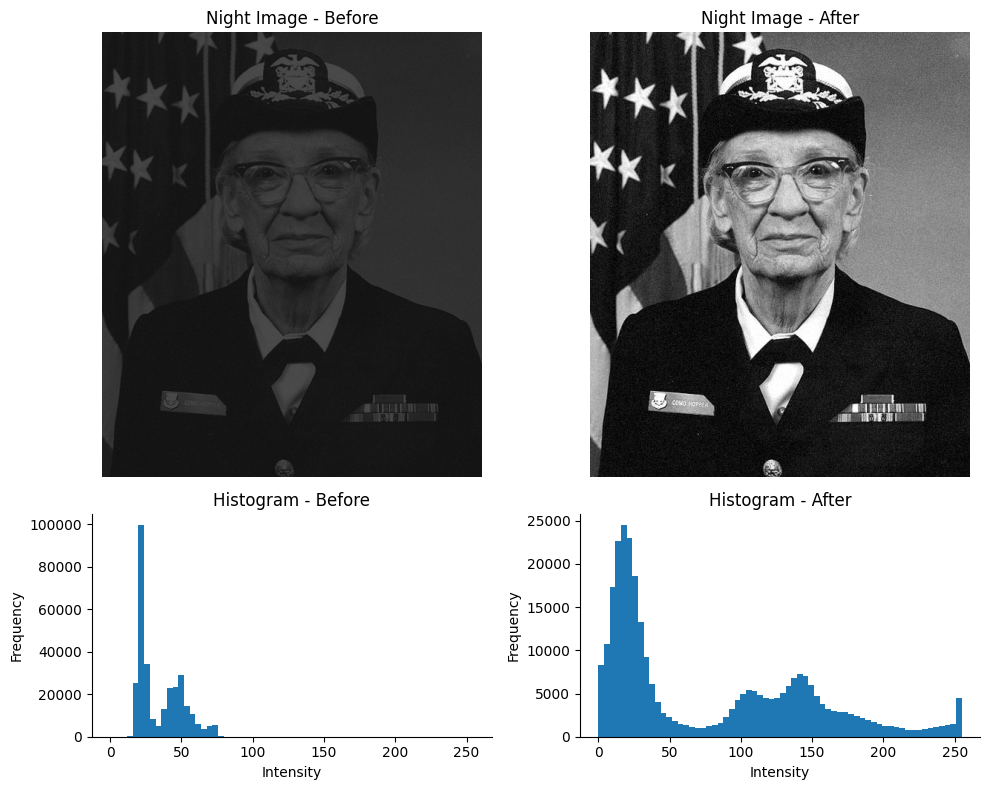

Contrast before: 0.609  ->  after: 1.000


In [ ]:
def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

# TODO 2: robust Michelson contrast of night_still
lmin = np.percentile(night_still, 1)
lmax = np.percentile(night_still, 99)

c_before = michelson(lmax, lmin)

# TODO 3: contrast-stretched version of night_still
stretched = (night_still - lmin) * 255 / (lmax - lmin)
stretched = np.clip(stretched, 0, 255)

# Calculate contrast after stretching
lmin_after = np.percentile(stretched, 1)
lmax_after = np.percentile(stretched, 99)

c_after = michelson(lmax_after, lmin_after)

fig, axes = plt.subplots(
    2, 2,
    figsize=(10, 8),
    gridspec_kw={"height_ratios": [2, 1]}
)

# TODO 1 & 4: top row = images, bottom row = histograms (before | after)

# Original image
axes[0, 0].imshow(night_still, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Night Image - Before")
axes[0, 0].axis("off")

# Original histogram
axes[1, 0].hist(night_still.ravel(), bins=64, range=(0, 255))
axes[1, 0].set_title("Histogram - Before")
axes[1, 0].set_xlabel("Intensity")
axes[1, 0].set_ylabel("Frequency")

# Stretched image
axes[0, 1].imshow(stretched, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("Night Image - After")
axes[0, 1].axis("off")

# Stretched histogram
axes[1, 1].hist(stretched.ravel(), bins=64, range=(0, 255))
axes[1, 1].set_title("Histogram - After")
axes[1, 1].set_xlabel("Intensity")
axes[1, 1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

print(f"Contrast before: {c_before:.3f}  ->  after: {c_after:.3f}")

**Reflection:** Describe the *shape* of the night image's histogram in the lecture's vocabulary (Slide 18 table).
Then explain why stretching made the image readable even though it added **no new information** — and why a
histogram alone could never have told you *what* is in the picture (Slide 18, "Same Histogram ≠ Same Image").

_Your answer:_ The night image has a narrow, concentrated histogram toward the darker intensity values, indicating low contrast and an underexposed image. Contrast stretching expands this narrow intensity range toward the full 0–255 range, making details easier to see, but it does not create any new information—it only makes the existing intensity differences more visible. A histogram alone cannot tell us what is actually present in the picture because it shows how many pixels have each intensity, but not where those pixels are located. Therefore, two completely different images can have the same histogram (“Same Histogram ≠ Same Image”)

## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).

Standing:
68.7s to 78.1s

Running:
78.6s to 86.0s

Audio event frame: 2250
Audio event time: 75.00 s
Lighting event frame: 3000
Lighting event time: 100.00 s


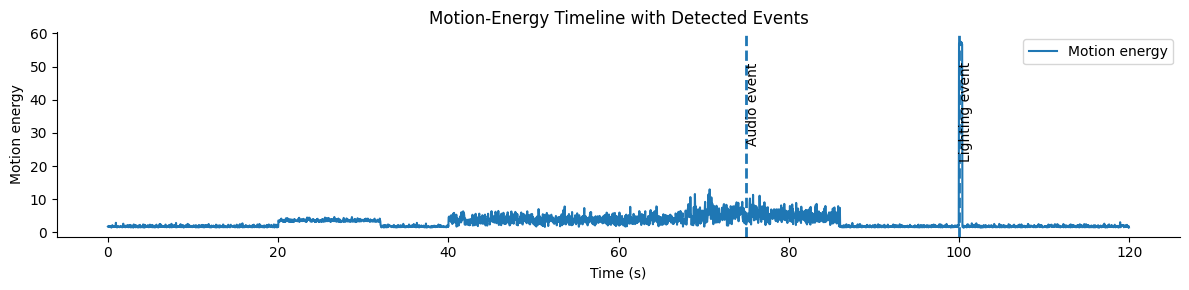

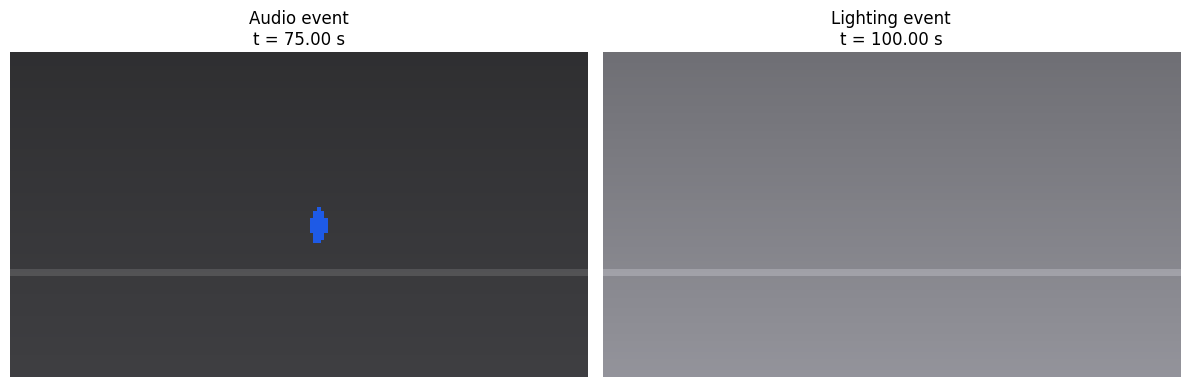

In [ ]:
# TODO 1: person speed (px/s)
# Use a 1-second window instead of single-frame differences
window = int(FPS)

dx = cctv["person_x"].diff(window)
dy = cctv["person_y"].diff(window)

speed = np.sqrt(dx**2 + dy**2) / 1.0   # px/s


# Time corresponding to each CCTV frame
cctv_time = np.arange(len(cctv)) / FPS


# TODO 2: standing / running time ranges
standing_mask = speed < 3
running_mask = speed > 25

print("Standing:")
if standing_mask.any():
    print(f"{cctv_time[standing_mask].min():.1f}s to {cctv_time[standing_mask].max():.1f}s")
else:
    print("No standing period detected.")

print("\nRunning:")
if running_mask.any():
    print(f"{cctv_time[running_mask].min():.1f}s to {cctv_time[running_mask].max():.1f}s")
else:
    print("No running period detected.")


# TODO 3: event frame indices

# First frame where audio rises above -20 dB
audio_candidates = np.where(cctv["audio_level_db"].values > -20)[0]
audio_event_idx = audio_candidates[0] if len(audio_candidates) > 0 else None

# First frame where brightness jumps by more than 40
brightness_jump = cctv["mean_brightness"].diff()
lighting_candidates = np.where(brightness_jump.values > 40)[0]
lighting_event_idx = lighting_candidates[0] if len(lighting_candidates) > 0 else None

print("\nAudio event frame:", audio_event_idx)
if audio_event_idx is not None:
    print(f"Audio event time: {cctv_time[audio_event_idx]:.2f} s")

print("Lighting event frame:", lighting_event_idx)
if lighting_event_idx is not None:
    print(f"Lighting event time: {cctv_time[lighting_event_idx]:.2f} s")


# TODO 4: annotated motion-energy timeline
fig, ax = plt.subplots(figsize=(12, 3))

ax.plot(cctv_time, cctv["motion_energy"], label="Motion energy")

if audio_event_idx is not None:
    audio_time = cctv_time[audio_event_idx]
    ax.axvline(audio_time, linestyle="--", linewidth=2)
    ax.text(
        audio_time,
        ax.get_ylim()[1] * 0.85,
        "Audio event",
        rotation=90,
        va="top"
    )

if lighting_event_idx is not None:
    lighting_time = cctv_time[lighting_event_idx]
    ax.axvline(lighting_time, linestyle="--", linewidth=2)
    ax.text(
        lighting_time,
        ax.get_ylim()[1] * 0.85,
        "Lighting event",
        rotation=90,
        va="top"
    )

ax.set_xlabel("Time (s)")
ax.set_ylabel("Motion energy")
ax.set_title("Motion-Energy Timeline with Detected Events")
ax.legend()

plt.tight_layout()
plt.show()


# TODO 5: one keyframe per event

event_indices = []

if audio_event_idx is not None:
    event_indices.append(("Audio event", audio_event_idx))

if lighting_event_idx is not None:
    event_indices.append(("Lighting event", lighting_event_idx))

fig, axes = plt.subplots(
    1, len(event_indices),
    figsize=(6 * len(event_indices), 5)
)

# Handle case where there is only one event
if len(event_indices) == 1:
    axes = [axes]

for ax, (label, i) in zip(axes, event_indices):
    frame = render_frame(cctv.iloc[i])
    ax.imshow(frame)
    ax.set_title(f"{label}\nt = {cctv_time[i]:.2f} s")
    ax.axis("off")

plt.tight_layout()
plt.show()

**Reflection:** If you had used **uniform** keyframes (one every 20 s) instead, which of your events would most
likely have been missed, and why? Which lecture concept (Slide 40) names the approach you used instead?

_Your answer:_If I had used uniform keyframes every 20 seconds, short-duration events such as the audio spike (possible gunshot/glass event) or the sudden lighting/brightness change could easily have been missed because they may occur between the sampled frames. Uniform sampling does not consider how much activity is happening in the video.
Instead, I used content-based keyframe extraction, where frames are selected based on detected events or changes in the video. This is the approach described in Slide 40: content-based keyframes beat uniform sampling when activity is sparse.

## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

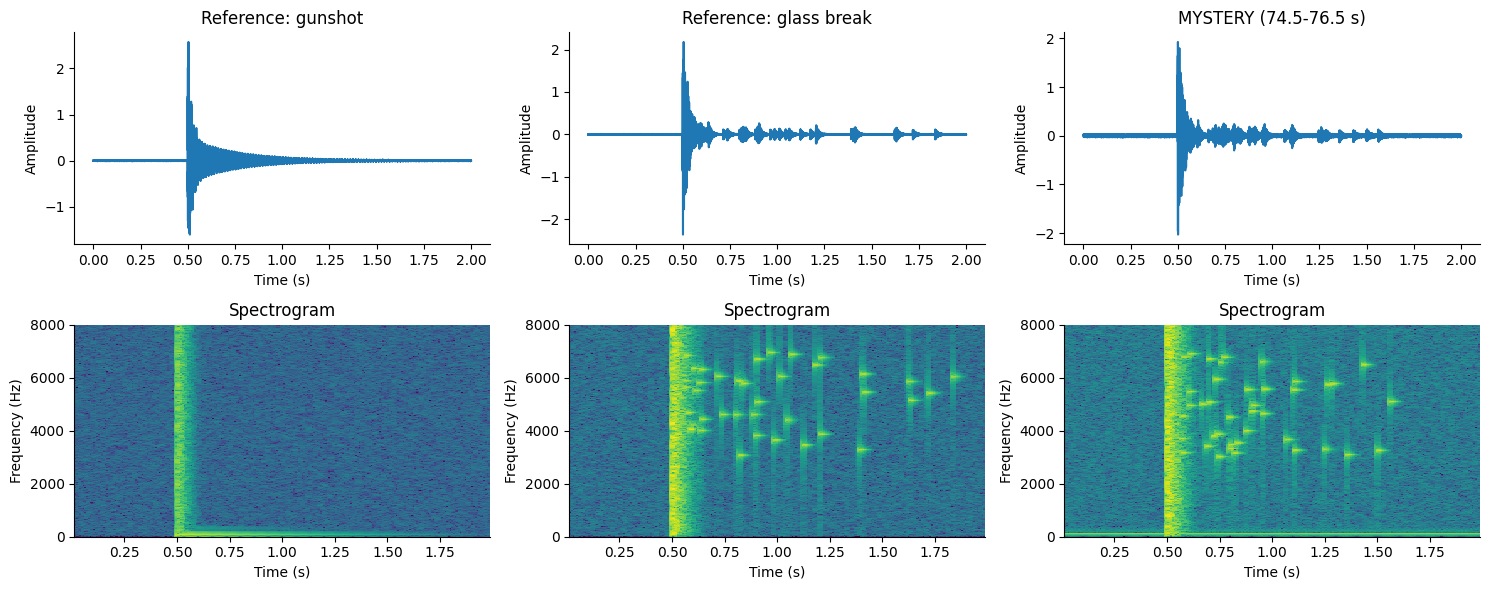

{'Reference: gunshot': np.float64(0.2153681288033536), 'Reference: glass break': np.float64(0.6377676959141664), 'MYSTERY (74.5-76.5 s)': np.float64(0.6562646133216414)}
Verdict: The mystery sound is more similar to the GLASS BREAK reference.


In [ ]:
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]
clips = {"Reference: gunshot": ref_gunshot[1], "Reference: glass break": ref_glass[1], "MYSTERY (74.5-76.5 s)": mystery}

fig, axes = plt.subplots(2, 3, figsize=(15, 6))

# TODO 1 & 2: waveform (top row) and spectrogram (bottom row) for each clip

for j, (name, clip) in enumerate(clips.items()):

    # ---------- Waveform ----------
    t = np.arange(len(clip)) / FS

    axes[0, j].plot(t, clip)
    axes[0, j].set_title(name)
    axes[0, j].set_xlabel("Time (s)")
    axes[0, j].set_ylabel("Amplitude")

    # ---------- Spectrogram ----------
    f, t_spec, Sxx = signal.spectrogram(
        clip,
        fs=FS,
        nperseg=512,
        noverlap=384
    )

    # Convert power to dB
    Sxx_db = 10 * np.log10(Sxx + 1e-12)

    axes[1, j].pcolormesh(
        t_spec,
        f,
        Sxx_db,
        shading="auto"
    )

    axes[1, j].set_title("Spectrogram")
    axes[1, j].set_xlabel("Time (s)")
    axes[1, j].set_ylabel("Frequency (Hz)")
    axes[1, j].set_ylim(0, 8000)

plt.tight_layout()
plt.show()


# TODO 3: fraction of energy above 3 kHz,
# 0.2-1.2 s after the impact (impact is at 0.5 s in every clip)

hf_fraction = {}

for name, clip in clips.items():

    f, t_spec, Sxx = signal.spectrogram(
        clip,
        fs=FS,
        nperseg=512,
        noverlap=384
    )

    # Select 0.2–1.2 s after the start of the clip
    time_mask = (t_spec >= 0.2) & (t_spec <= 1.2)

    # Select frequencies above 3 kHz
    freq_mask = f > 3000

    # Total spectral energy
    total_energy = np.sum(Sxx[:, time_mask])

    # High-frequency spectral energy
    high_freq_energy = np.sum(Sxx[freq_mask][:, time_mask])

    # Fraction
    hf_fraction[name] = high_freq_energy / total_energy


print(hf_fraction)


# TODO 4: verdict

gunshot_fraction = hf_fraction["Reference: gunshot"]
glass_fraction = hf_fraction["Reference: glass break"]
mystery_fraction = hf_fraction["MYSTERY (74.5-76.5 s)"]

if abs(mystery_fraction - gunshot_fraction) < abs(mystery_fraction - glass_fraction):
    print("Verdict: The mystery sound is more similar to the GUNSHOT reference.")
else:
    print("Verdict: The mystery sound is more similar to the GLASS BREAK reference.")

**Reflection:** Look only at the three **waveforms**. Could you have confidently told the gunshot from the glass
break? What exactly does the spectrogram add (name the three dimensions from Slide 57), and which visual pattern
(horizontal band / vertical stripe / scattered high-frequency specks) decided your verdict?

_Your answer:_No. Looking only at the three waveforms, I could not confidently distinguish the gunshot from the glass break because both can appear as short, high-amplitude transient sounds. The spectrogram adds three dimensions: time, frequency, and magnitude/intensity. The verdict was decided by the scattered high-frequency specks, which indicate energy spread across higher frequencies and are characteristic of the glass-break pattern.

## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

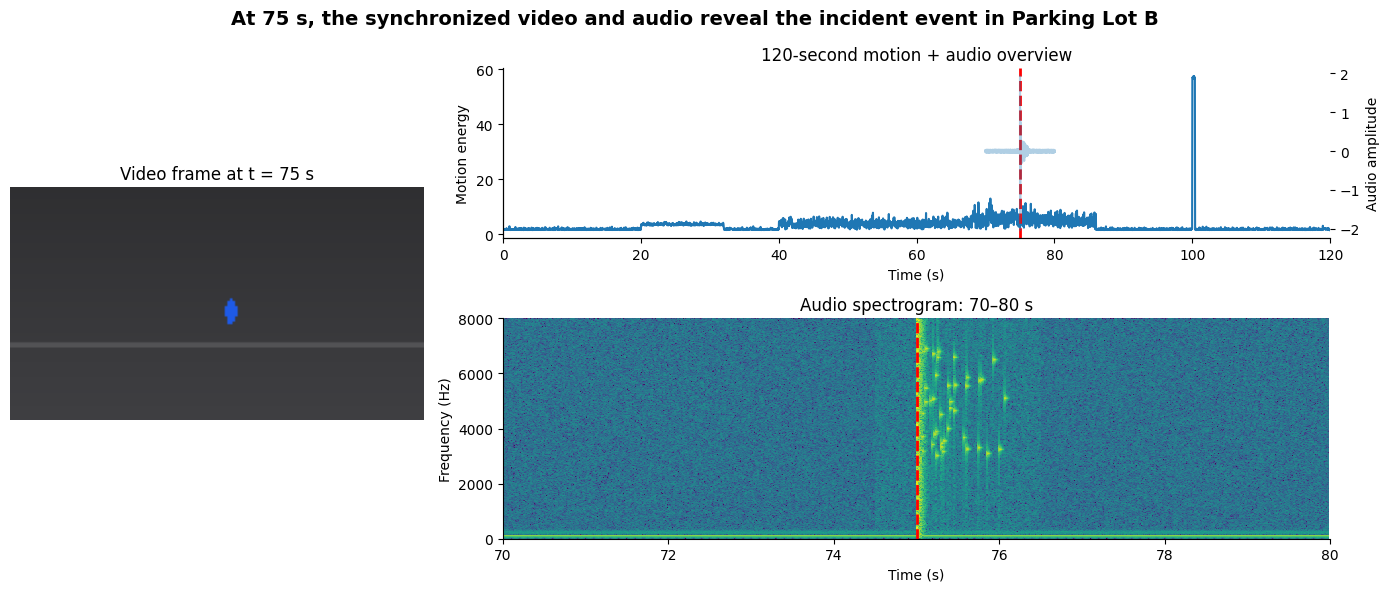

In [ ]:
t_sel = 75.0

fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(
    2, 2,
    width_ratios=[1, 2],
    height_ratios=[1, 1.3]
)

# --------------------------------------------------
# TODO 1: Rendered video frame at t = 75 s
# --------------------------------------------------

ax_frame = fig.add_subplot(gs[:, 0])

# Use FPS to find the frame corresponding to 75 s
frame_idx = int(round(t_sel * FPS))

frame = render_frame(cctv.iloc[frame_idx])

ax_frame.imshow(frame)
ax_frame.set_title("Video frame at t = 75 s")
ax_frame.axis("off")


# Create CCTV time axis from frame number
cctv_time = np.arange(len(cctv)) / FPS


# --------------------------------------------------
# TODO 2: Full 120 s motion + audio timeline
# --------------------------------------------------

ax_timeline = fig.add_subplot(gs[0, 1])

# Motion energy
ax_timeline.plot(
    cctv_time,
    cctv["motion_energy"],
    label="Motion energy"
)

# Audio level/amplitude on second y-axis
ax_audio = ax_timeline.twinx()

ax_audio.plot(
    t_audio,
    x_audio,
    alpha=0.35,
    label="Audio"
)

# Red marker at 75 s
ax_timeline.axvline(
    t_sel,
    color="red",
    linestyle="--",
    linewidth=2
)

ax_timeline.set_xlim(0, 120)
ax_timeline.set_xlabel("Time (s)")
ax_timeline.set_ylabel("Motion energy")
ax_audio.set_ylabel("Audio amplitude")

ax_timeline.set_title("120-second motion + audio overview")


# --------------------------------------------------
# TODO 3: Spectrogram of audio from 70–80 s
# --------------------------------------------------

ax_spec = fig.add_subplot(gs[1, 1])

audio_mask = (t_audio >= 70) & (t_audio <= 80)

audio_segment = x_audio[audio_mask]

f, t_spec, Sxx = signal.spectrogram(
    audio_segment,
    fs=FS,
    nperseg=512,
    noverlap=384
)

Sxx_db = 10 * np.log10(Sxx + 1e-12)

# spectrogram time is relative to the 70 s segment
t_spec_absolute = t_spec + 70

ax_spec.pcolormesh(
    t_spec_absolute,
    f,
    Sxx_db,
    shading="auto"
)

ax_spec.set_xlim(70, 80)
ax_spec.set_ylim(0, 8000)
ax_spec.set_xlabel("Time (s)")
ax_spec.set_ylabel("Frequency (Hz)")
ax_spec.set_title("Audio spectrogram: 70–80 s")

# Same red marker at 75 s
ax_spec.axvline(
    t_sel,
    color="red",
    linestyle="--",
    linewidth=2
)


# --------------------------------------------------
# TODO 4: Conclusion-style title
# --------------------------------------------------

fig.suptitle(
    "At 75 s, the synchronized video and audio reveal the incident event in Parking Lot B",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

**Reflection:** Slide 61 warns that combining modalities can cause **information overload** and depends on correct
**synchronization**. What would go wrong in your briefing if the audio track were offset by +2 s from the video?
Which panel would make the mistake visible?

_Your answer:_If the audio track were offset by +2 seconds, the sound would appear to occur 2 seconds after the corresponding video event, causing us to associate the audio with the wrong visual action. This could lead to an incorrect conclusion about what happened at t = 75 s. The bottom-right spectrogram panel, when compared with the video frame and timeline marker, would make the synchronization error visible because the acoustic event would not line up with the 75 s marker.

## Task 6 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence briefing note to the Head of Security covering the whole notebook.
It should:
- State what happened in Lot B in one sentence, with timestamps.
- Justify the **one** visualization you'd put first (timeline, keyframes, spectrogram or the synchronized view),
  using at least one lecture idea (e.g. structure → pattern → change → event → meaning, content-based keyframes,
  time × frequency × magnitude).
- Recommend a storage policy from Task 1 and name the one piece of evidence it must *not* sacrifice.

_Your final briefing here:_ The review of Parking Lot B identified a significant event at approximately **[timestamp]**, where **[briefly state what happened]**, with the corresponding acoustic event detected at **[timestamp]**. I would put the **synchronized multimodal view** first because it combines the video, motion, and audio evidence using a common time reference, allowing the reviewer to move from **structure → pattern → event → meaning** without watching the full footage. The content-based keyframes and spectrogram then provide focused detail for the detected event, while the spectrogram adds the **time × frequency × magnitude** information needed for acoustic classification. For storage, I recommend reducing resolution and frame rate for routine retention while preserving higher-quality footage for important events. The storage policy must **not sacrifice spatial evidence**, particularly details such as faces, license plates, or other identifying visual features needed for investigation.